## Post-stack inversion - Hess model

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import os
import random
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import scipy as sp
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import segyio
import torch

from scipy.signal import filtfilt
from scipy.ndimage import gaussian_filter
from mpl_toolkits.axes_grid1.inset_locator import mark_inset

from pylops.basicoperators import *
from pylops.signalprocessing import *
from pylops.utils.wavelets import *
from pylops.avo.poststack import *
from pylops.basicoperators import VStack as VStacklop

from pyproximal.proximal import *
from pyproximal import ProxOperator
from pyproximal.optimization.primal import *
from pyproximal.optimization.primaldual import *
from pyproximal.optimization.bregman import *
from pyproximal.optimization.segmentation import *

from torch.optim.lr_scheduler import CosineAnnealingLR
from torch.optim import Adam, SGD, RMSprop, RAdam
from pnpsvgd.model import UNetRes
from pnpsvgd.denoiser import *
from pnpsvgd.utils import *
from pnpsvgd.pnpseismic import _Denoise
from pnpsvgd.pnpseismic import *
from pnpsvgd.svgd import *

# random seed
np.random.seed(10)
random.seed(10)
torch.manual_seed(10)
torch.cuda.manual_seed_all(10)

# plotting setting
plt.style.use('seaborn-ticks')
matplotlib.rc('xtick', labelsize=13) 
matplotlib.rc('ytick', labelsize=13) 
plt.rc('font', size=15)
plt.rc('axes', titlesize=15)
plt.rc('axes', labelsize=15)

# gpu setting
os.environ["CUDA_DEVICE_ORDER"] = "PCI_BUS_ID"
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
device = torch.device('cuda')

print("Current working directory: {0}".format(os.getcwd()))

Current working directory: /home/izzatum/Desktop/pnp-svgd/notebooks


## Hess model

In [2]:
f = segyio.open('../data/timodel_vp.segy', ignore_geometry=True)
v = segyio.collect(f.trace[:]).T
v = np.pad(v, ((80, 0), (0, 0)), constant_values=v[0, 0])
v = v[::8, ::8]

nt0, nx = v.shape
dt0 = 0.008
t0 = np.arange(nt0)*dt0
dx = 4
x = np.arange(nx)*dx

rho = 2000.
m = np.log(v*rho)

Compute data

In [3]:
# smooth model
nsmooth = 30
mback = filtfilt(np.ones(nsmooth)/float(nsmooth), 1,
                 filtfilt(np.ones(nsmooth)/float(nsmooth), 1, m, axis=0), axis=1)

# wavelet
ntwav = 61
wav, twav, wavc = ricker(t0[:ntwav//2+1], 8)

# operator
Lop = PoststackLinearModelling(wav / 2, nt0=nt0, spatdims=nx)

# data
d = Lop * m.ravel()

# colored noise
sigman = 1e-1
n = filtfilt(np.ones(10)/10, 1,
             filtfilt(np.ones(5)/5, 1, np.random.normal(0, sigman, (nt0, nx)).T, method='gust').T,
             method='gust').ravel()
dn = d + n

# background data
dback = Lop * mback.ravel()

d = d.reshape(nt0, nx)
dn = dn.reshape(nt0, nx)
dback = dback.reshape(nt0, nx)

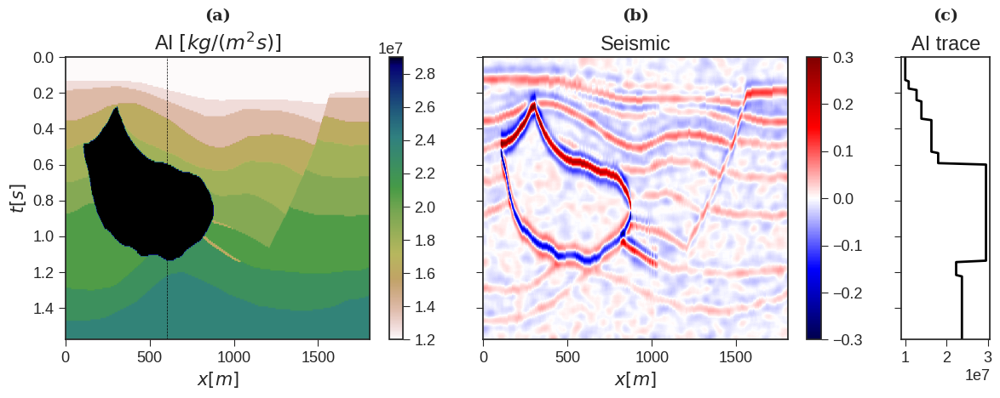

In [4]:
cmap='gist_earth_r'

fig, axs = plt.subplots(1, 3, sharey=True, 
                        gridspec_kw={'width_ratios': [3, 3, 0.7]}, figsize=(12, 5))
im = axs[0].imshow(np.exp(m), vmin=1.2e7, vmax=2.9e7,
                   cmap=cmap, extent=(x[0], x[-1], t0[-1], t0[0]))
axs[0].axvline(x[nx//3], c='k', ls='--', lw=0.5)
axs[0].text(0.5, 1.13, '(a)', ha='center', fontsize=14, fontweight='bold', 
            family='serif', transform=axs[0].transAxes)
plt.colorbar(im, ax=axs[0])
axs[0].axis('tight')
axs[0].set_ylabel(r'$t [s]$')
axs[0].set_xlabel(r'$x [m]$')
axs[0].set_title(r'AI $[kg/(m^2s)]$', fontsize=17)
axs[0].set_aspect('auto', 'datalim')

im = axs[1].imshow(dn, cmap='seismic', vmin=-0.3, vmax=0.3, extent=(x[0], x[-1], t0[-1], t0[0]))
axs[1].set_xlabel(r'$x [m]$')
axs[1].set_title('Seismic', fontsize=17)
axs[1].text(0.5, 1.13, '(b)', ha='center', fontsize=14, fontweight='bold', 
            family='serif', transform=axs[1].transAxes)
axs[1].axis('tight')
axs[1].set_aspect('auto', 'datalim')

plt.colorbar(im, ax=axs[1])
axs[2].plot(np.exp(m[:, nx//3]), t0, 'k', lw=2)
axs[2].axis('tight')
axs[2].set_title('AI trace', fontsize=17)
axs[2].text(0.5, 1.13, '(c)', ha='center', fontsize=14, fontweight='bold', 
            family='serif', transform=axs[2].transAxes)
axs[2].set_aspect('auto', 'datalim')
plt.tight_layout()
# plt.savefig('Figs/hess2_modeldata.eps', dpi=80);

## DRUNet Loading

In [5]:
# Pre-trained DRUNet
model_02 = UNetRes(in_nc=2)
# Download drunet_gray.pth from https://drive.google.com/drive/folders/1uEYx0GR4D7q5UMsc1qFVW1KeyVYI_hE-?usp=sharing
# and place it on /models directory
model_02.load_state_dict(torch.load('../models/drunet_gray.pth'))
model_02.eval().to(device).half();

## SVGD with Gaussian prior and TV

In [6]:
num_particles = 100

# prior
x0 = torch.from_numpy(mback.ravel())
sigma0 = 0.5*torch.ones(nt0*nx) # with smooth
prior = torch.distributions.Normal(x0, sigma0)

# prior TV
Gop = Gradient(dims=(nt0, nx), edge=True, dtype=Lop.dtype, kind='forward')
Gop_torch = TorchOperator(Gop, batch=True)

sigmatv = 0.01*torch.ones(2*nt0*nx)
prior1 = torch.distributions.Laplace(torch.zeros(2*nt0*nx), sigmatv)

# likelihood ** very large impact on the choice of noise std vs prior std
dtorch = torch.from_numpy(d.ravel())
Cd = 0.01*torch.ones(nt0*nx)
likelihood = torch.distributions.Normal(dtorch, Cd)

# PyTorch operator
Lop_torch = TorchOperator(Lop, batch=True)

# posterior
gpost = PosteriorDistribution(x0, sigma0, dtorch, Lop_torch, Cd,
                              xtv=torch.zeros(2*nt0*nx), Gtv=Gop_torch, Ctv=sigmatv,
                              verb=False)

# SVGD Kernel
K = RBF()

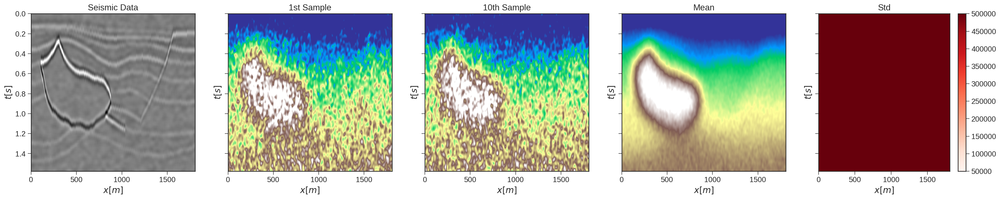

In [7]:
# prior samples
X_init = prior.sample_n(num_particles)
X_init = torch.from_numpy(np.vstack([sp.ndimage.gaussian_filter(X_init[i].numpy().reshape(nt0,nx), 2).ravel()
                                     for i in range(num_particles)]))

fig, axs = plt.subplots(1, 5, sharey=True, figsize=(30, 5), dpi=150)
axs[0].imshow(dn, cmap='gray', vmin=-0.3, vmax=0.3, interpolation='sinc',
              extent=(x[0], x[-1], t0[-1], t0[0]))
axs[0].set_title('Seismic Data')
axs[0].set_ylabel(r'$t [s]$')
axs[0].set_xlabel(r'$x [m]$')
axs[0].axis('tight')
axs[0].set_aspect('auto', 'datalim')

axs[1].imshow(np.exp(X_init[0].detach().numpy().reshape(nt0, nx)), cmap='terrain', vmin=1.2e7, vmax=2.9e7,
              interpolation='sinc', extent=(x[0], x[-1], t0[-1], t0[0]))
axs[1].set_title('1st Sample')
axs[1].set_ylabel(r'$t [s]$')
axs[1].set_xlabel(r'$x [m]$')
axs[1].axis('tight')
axs[1].set_aspect('auto', 'datalim')

axs[2].imshow(np.exp(X_init[10].detach().numpy().reshape(nt0, nx)), cmap='terrain', vmin=1.2e7, vmax=2.9e7,
              interpolation='sinc', extent=(x[0], x[-1], t0[-1], t0[0]))
axs[2].set_title('10th Sample')
axs[2].set_ylabel(r'$t [s]$')
axs[2].set_xlabel(r'$x [m]$')
axs[2].axis('tight')
axs[2].set_aspect('auto', 'datalim')

axs[3].imshow(torch.exp(X_init).mean(0).detach().numpy().reshape(nt0, nx), cmap='terrain', vmin=1.2e7, vmax=2.9e7, 
              interpolation='sinc', extent=(x[0], x[-1], t0[-1], t0[0]))
axs[3].set_title('Mean')
axs[3].set_ylabel(r'$t [s]$')
axs[3].set_xlabel(r'$x [m]$')
axs[3].axis('tight')
axs[3].set_aspect('auto', 'datalim')

im = axs[4].imshow(torch.exp(X_init).std(0).detach().numpy().reshape(nt0, nx), cmap='Reds', vmin=5e4, vmax=5e5,
              interpolation='sinc', extent=(x[0], x[-1], t0[-1], t0[0]))
axs[4].set_title('Std')
axs[4].set_ylabel(r'$t [s]$')
axs[4].set_xlabel(r'$x [m]$')
axs[4].axis('tight')
axs[4].set_aspect('auto', 'datalim')
plt.colorbar(im, ax=axs[4]);

Iter 0: LogP=125848349.925
Iter 10: LogP=-81800350.466
Iter 20: LogP=-87615310.882
Iter 30: LogP=-83265377.449
Iter 40: LogP=-91406779.900
Iter 50: LogP=-92706371.461
Execution time: 229.9004511833191 seconds


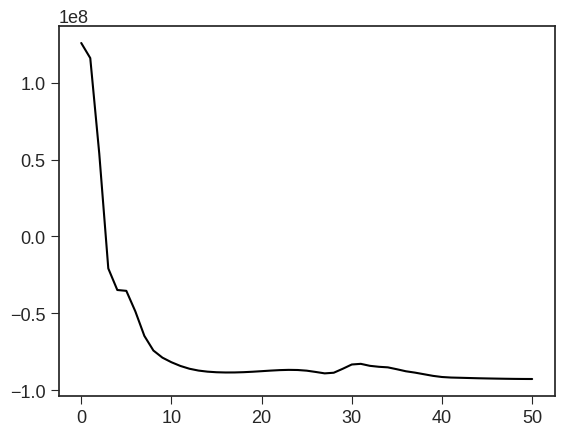

In [8]:
X = X_init.clone()
mu = .11 
sigma = .01
lr = 1e-1
niter = 51

denoiser_dn = lambda x: apply_DRUNET(model_02, x.to(device), mu, sigma, m.shape, edge_max=512, verb=False)
optimizer = Adam([X], lr=lr)
scheduler = CosineAnnealingLR(optimizer, 20, eta_min=0, last_epoch=- 1, verbose=False)
svgd = PnPSVGD(denoiser_dn, gpost, K, optimizer, scheduler=scheduler, loops=5)

log_prob = []
Xmeancol = []
Xstdcol = []

# get the start time
st = time.time()
for iiter in range(niter):
    lp = svgd.step(X)
    log_prob.append(-lp)
    if iiter % 10 == 0:
        print(f'Iter {iiter}: LogP={-lp:.3f}')
        Xmeancol.append(torch.exp(X).mean(0).detach().numpy())
        Xstdcol.append(torch.exp(X).std(0).detach().numpy())

# get the end time
et = time.time()

Xmeancol.append(torch.exp(X).mean(0).detach().numpy())
Xstdcol.append(torch.exp(X).std(0).detach().numpy())

Xmeancol.pop(-2)
Xstdcol.pop(-2)

# get the execution time
elapsed_time = et - st
print('Execution time:', elapsed_time, 'seconds')
        
plt.figure()
plt.plot(log_prob, 'k');

## Vanilla SVGD

Iter 0: LogP=125848349.925
Iter 10: LogP=-16493343.546
Iter 20: LogP=-61928058.514
Iter 30: LogP=-79725800.873
Iter 40: LogP=-87919687.841
Iter 50: LogP=-90625621.059
Execution time: 83.54066467285156 seconds


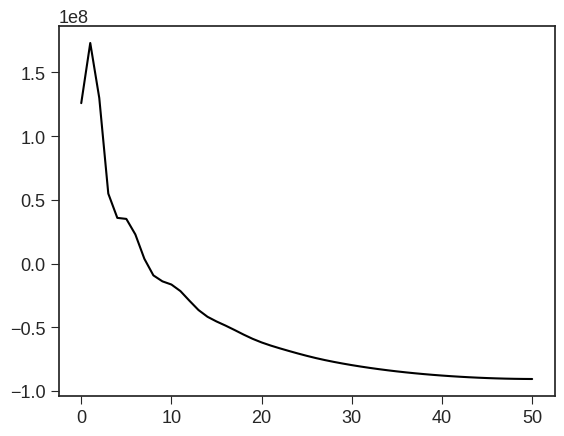

In [9]:
Xsvgd = X_init.clone()
lr = 1e-1
niter = 51

optimizer = Adam([Xsvgd], lr=lr)
scheduler = CosineAnnealingLR(optimizer, niter, eta_min=0, last_epoch=- 1, verbose=False)
svgd = SVGD(gpost, K, optimizer, scheduler=scheduler)

log_prob = []
Xsvgdmeancol = []
Xsvgdstdcol = []

# get the start time
st = time.time()
for iiter in range(niter):
    lp = svgd.step(Xsvgd)
    log_prob.append(-lp)
    if iiter % 10 == 0:
        print(f'Iter {iiter}: LogP={-lp:.3f}')
        Xsvgdmeancol.append(torch.exp(Xsvgd.data).mean(0).detach().numpy())
        Xsvgdstdcol.append(torch.exp(Xsvgd.data).std(0).detach().numpy())

# get the end time
et = time.time()

# get the execution time
elapsed_time = et - st
print('Execution time:', elapsed_time, 'seconds')
        
plt.figure()
plt.plot(log_prob, 'k');

## Optimization

In [10]:
l2 = L2(Op=Lop, b=dn.ravel(), niter=20, warm=True)

Dop = Gradient(dims=(nt0, nx), edge=True, dtype=Lop.dtype, kind='backward')
Iop = Identity(m.size)
Kop = VStacklop([Iop, Dop])

sigma_tv = 1e-2
l1 = L21(ndim=2, sigma=sigma_tv)

L = 9.
tau = 1.
mu = 0.99 / (tau * L) #tau*mu*L<=1

sigma = 0.3
denoiser_dn = lambda x, tau: apply_DRUNET_optimization(model_02,
                                                       torch.from_numpy(x).float(),
                                                       mu,
                                                       sigma,
                                                       edge_max=512,
                                                       verb=False)
g = VStack([_Denoise(denoiser_dn, dims=m.shape), l1], nn=[nx*nt0, 2*nx*nt0])

m_pshist = []
y_pshist = []
rre_pshist = [np.linalg.norm(m-mback)/np.linalg.norm(m), ]
rrey_pshist = [np.linalg.norm(m-mback)/np.linalg.norm(m), ]
mdrunet = PrimalDual_(l2, g, Kop, x0=mback.ravel(), tau=tau, mu=mu,
                  niter=100, show=True,
                  callback=lambda xx, yy: callback(xx, yy, m.ravel(), m_pshist, 
                                                   y_pshist, rre_pshist, rrey_pshist))
mdrunet = mdrunet.reshape(m.shape)

Primal-dual: min_x f(Ax) + x^T z + g(x)
---------------------------------------------------------
Proximal operator (f): <class 'pyproximal.proximal.L2.L2'>
Proximal operator (g): <class 'pyproximal.proximal.VStack.VStack'>
Linear operator (A): <class 'pylops.basicoperators.VStack.VStack'>
Additional vector (z): None
tau = 1.000000e+00	mu = 1.100000e-01
theta = 1.00		niter = 100

   Itn       x[0]          f           g          z^x       J = f + g + z^x
     1   1.61217e+01   1.916e+01   7.013e+00   0.000e+00       2.617e+01
     2   1.61308e+01   1.000e+01   8.071e+00   0.000e+00       1.808e+01
     3   1.61422e+01   7.152e+00   8.293e+00   0.000e+00       1.544e+01
     4   1.61529e+01   6.104e+00   8.135e+00   0.000e+00       1.424e+01
     5   1.61632e+01   5.617e+00   7.914e+00   0.000e+00       1.353e+01
     6   1.61718e+01   5.535e+00   7.663e+00   0.000e+00       1.320e+01
     7   1.61780e+01   5.454e+00   7.506e+00   0.000e+00       1.296e+01
     8   1.61818e+01   5.543e+

## Save Results

In [11]:
np.savez('../figures/hess/hess_results', 
        X_init=X_init.detach().numpy(), 
        X=X.detach().numpy(),
        Xmeancol=Xmeancol,
        Xstdcol=Xstdcol,
        Xsvgd=Xsvgd.detach().numpy(),
        Xsvgdmeancol=Xsvgdmeancol,
        Xsvgdstdcol=Xsvgdstdcol,
        mdrunet=mdrunet)

## Plotting

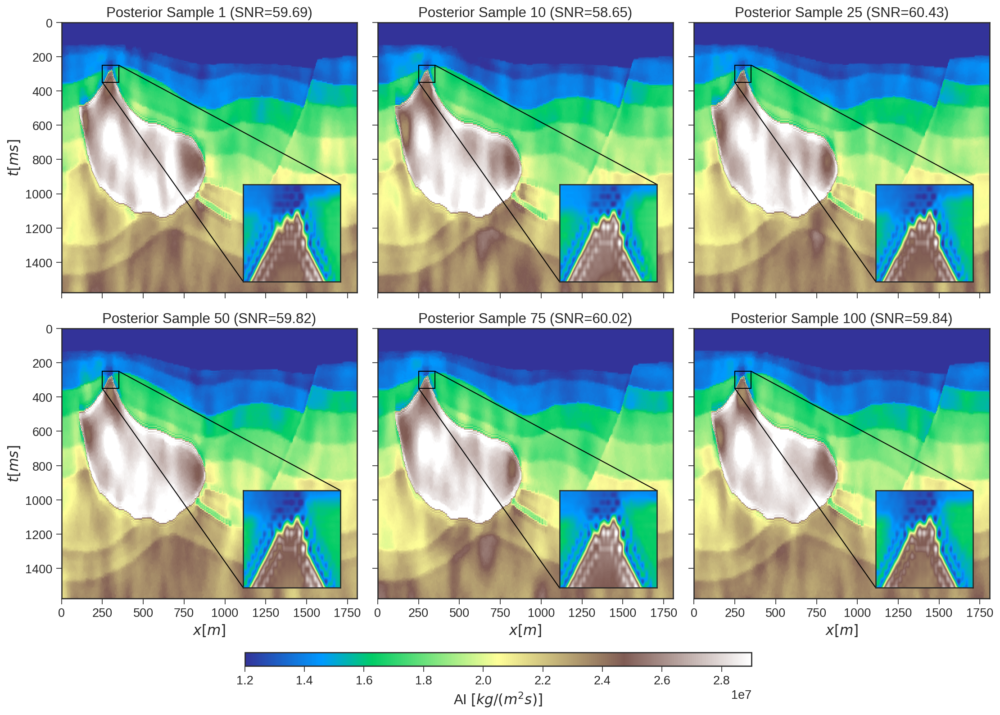

In [12]:
# svgd
plt.rcParams['font.size'] = '15'

iiter = np.array([1, 10, 25, 50, 75, 100])
fig, axs = plt.subplots(2, 3, sharex=True, sharey=True, figsize=(15,10), dpi=150)
axs = axs.ravel()
vmin, vmax = 1.2e7, 2.9e7
for i, k in enumerate(iiter):
    axi=axs[i].imshow(np.exp(Xsvgd[i]).reshape(nt0, nx), 
                      vmin=vmin, vmax=vmax, cmap="terrain",
                      interpolation='sinc', extent=(x[0], x[-1], t0[-1]*1000, t0[0]*1000))
    axs[i].set_title(f'Posterior Sample {k} (SNR={snr(np.exp(m).ravel(), np.exp(Xsvgd[i].numpy().ravel())):.2f})')
    axs[i].axis('tight')
    axs[i].set_aspect('auto', 'datalim')
    
    axins = axs[i].inset_axes([0.6, 0.04, 0.36, 0.36])
    axins.imshow(np.exp(Xsvgd[i]).reshape(nt0, nx), 
                 vmin=vmin, vmax=vmax, cmap="terrain",
                 interpolation='sinc', extent=(x[0], x[-1], t0[-1]*1000, t0[0]*1000))
    # sub region of the original image
    x1, x2, y1, y2 = 250, 350, 250, 350
    axins.set_xlim(x1, x2)
    axins.set_ylim(y2, y1)
    axins.set_xticklabels([])
    axins.set_yticklabels([])
    axins.set_xticks([])
    axins.set_yticks([])

    _patch, pp1, pp2 = mark_inset(axs[i], axins, loc1=1, loc2=3, fc="none", ec="black")
    pp1.loc1, pp1.loc2 = 1, 4
    pp2.loc1, pp2.loc2 = 3, 2

axs[0].set_ylabel(r'$t [ms]$')
axs[3].set_ylabel(r'$t [ms]$')
axs[3].set_xlabel(r'$x [m]$')
axs[4].set_xlabel(r'$x [m]$')
axs[5].set_xlabel(r'$x [m]$')
fig.tight_layout()
fig.subplots_adjust(bottom=0.1)
cbar_ax = fig.add_axes([0.25, 0.0001, 0.5, 0.02])
cbar = fig.colorbar(axi, cax=cbar_ax, orientation='horizontal')
cbar.set_label(r'AI $[kg/(m^2s)]$')
# plt.savefig('../figures/hess/3-1-hess-svgd-samples.eps', dpi=300, bbox_inches="tight")
# plt.savefig('../figures/hess/3-1-hess-svgd-samples.png', dpi=300, bbox_inches="tight")

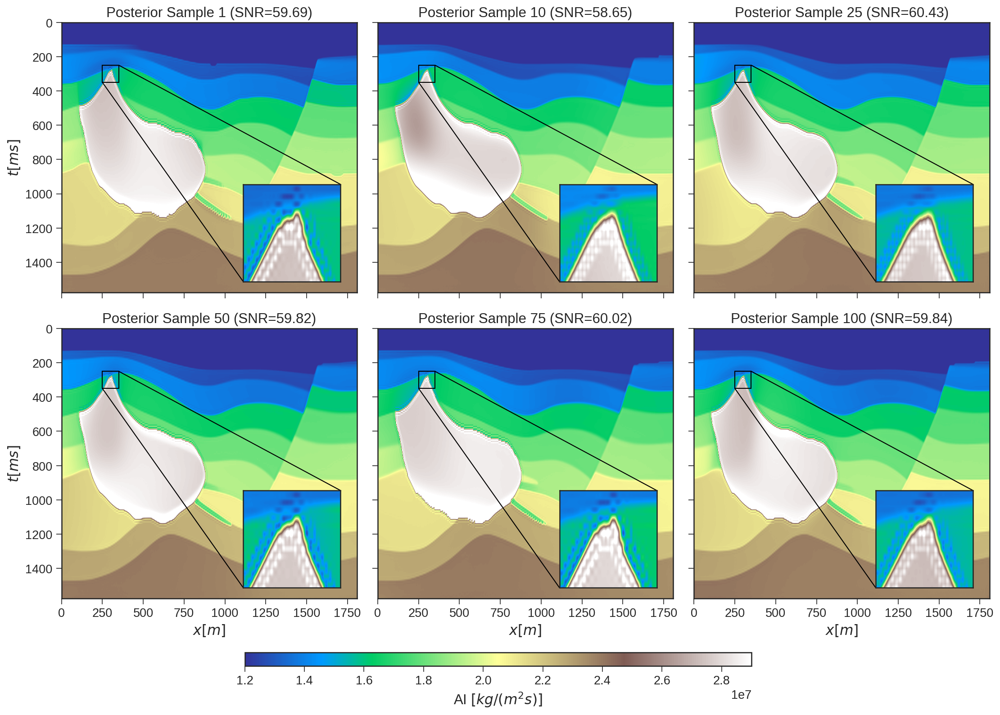

In [13]:
plt.rcParams['font.size'] = '15'

iiter = np.array([1, 10, 25, 50, 75, 100])
fig, axs = plt.subplots(2, 3, sharex=True, sharey=True, figsize=(15,10), dpi=150)
axs = axs.ravel()
vmin, vmax = 1.2e7, 2.9e7
for i, k in enumerate(iiter):
    axi=axs[i].imshow(np.exp(X[i]).reshape(nt0, nx), 
                      vmin=vmin, vmax=vmax, cmap="terrain",
                      interpolation='sinc', extent=(x[0], x[-1], t0[-1]*1000, t0[0]*1000))
    axs[i].set_title(f'Posterior Sample {k} (SNR={snr(np.exp(m).ravel(), np.exp(Xsvgd[i].numpy().ravel())):.2f})')
    axs[i].axis('tight')
    axs[i].set_aspect('auto', 'datalim')
    
    axins = axs[i].inset_axes([0.6, 0.04, 0.36, 0.36])
    axins.imshow(np.exp(X[i]).reshape(nt0, nx), 
                 vmin=vmin, vmax=vmax, cmap="terrain",
                 interpolation='sinc', extent=(x[0], x[-1], t0[-1]*1000, t0[0]*1000))
    # sub region of the original image
    x1, x2, y1, y2 = 250, 350, 250, 350
    axins.set_xlim(x1, x2)
    axins.set_ylim(y2, y1)
    axins.set_xticklabels([])
    axins.set_yticklabels([])
    axins.set_xticks([])
    axins.set_yticks([])

    _patch, pp1, pp2 = mark_inset(axs[i], axins, loc1=1, loc2=3, fc="none", ec="black")
    pp1.loc1, pp1.loc2 = 1, 4
    pp2.loc1, pp2.loc2 = 3, 2

axs[0].set_ylabel(r'$t [ms]$')
axs[3].set_ylabel(r'$t [ms]$')
    
axs[3].set_xlabel(r'$x [m]$')
axs[4].set_xlabel(r'$x [m]$')
axs[5].set_xlabel(r'$x [m]$')
fig.tight_layout()
fig.subplots_adjust(bottom=0.1)
cbar_ax = fig.add_axes([0.25, 0.0001, 0.5, 0.02])
cbar = fig.colorbar(axi, cax=cbar_ax, orientation='horizontal')
cbar.set_label(r'AI $[kg/(m^2s)]$')
# plt.savefig('../figures/hess/3-1-hess-samples.eps', dpi=300, bbox_inches="tight")
# plt.savefig('../figures/hess/3-1-hess-samples.png', dpi=300, bbox_inches="tight")

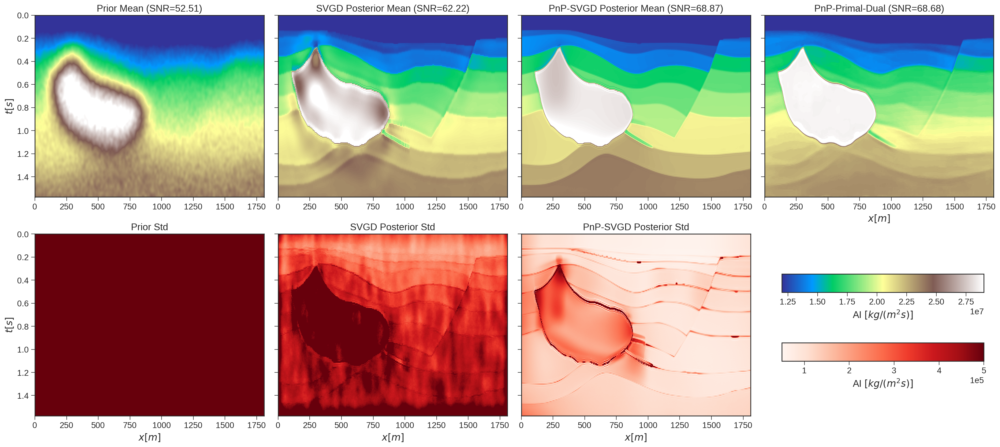

In [14]:
fig, axs = plt.subplots(2, 4, sharey=True, figsize=(22, 10), dpi=150)
axs = axs.ravel()
axi = axs[0].imshow(torch.exp(X_init).mean(0).detach().numpy().reshape(nt0, nx), 
                    cmap='terrain', vmin=1.2e7, vmax=2.9e7,
                    interpolation='sinc', extent=(x[0], x[-1], t0[-1], t0[0]))
axs[0].set_title(f'Prior Mean (SNR={snr(np.exp(m).ravel(), torch.exp(X_init).mean(0).detach().numpy().ravel()):.2f})')
axs[0].set_ylabel(r'$t [s]$')
# axs[0].set_xlabel(r'$x [m]$')
axs[0].axis('tight')
axs[0].set_aspect('auto', 'datalim')

axs[1].imshow(torch.exp(Xsvgd).mean(0).detach().numpy().reshape(nt0, nx), cmap='terrain', vmin=1.2e7, vmax=2.9e7,
              interpolation='sinc', extent=(x[0], x[-1], t0[-1], t0[0]))
axs[1].set_title(f'SVGD Posterior Mean (SNR={snr(np.exp(m).ravel(), torch.exp(Xsvgd).mean(0).detach().numpy().ravel()):.2f})')
# axs[1].set_ylabel(r'$t [ms]$')
# axs[1].set_xlabel(r'$x [m]$')
axs[1].axis('tight')
axs[1].set_aspect('auto', 'datalim')

axs[2].imshow(torch.exp(X).mean(0).detach().numpy().reshape(nt0, nx), cmap='terrain', vmin=1.2e7, vmax=2.9e7,
              interpolation='sinc', extent=(x[0], x[-1], t0[-1], t0[0]))
axs[2].set_title(f'PnP-SVGD Posterior Mean (SNR={snr(np.exp(m).ravel(), torch.exp(X).mean(0).detach().numpy().ravel()):.2f})')
# axs[2].set_ylabel(r'$t [ms]$')
# axs[2].set_xlabel(r'$x [m]$')
axs[2].axis('tight')
axs[2].set_aspect('auto', 'datalim')

im = axs[3].imshow(np.exp(mdrunet.reshape(nt0, nx)), cmap='terrain', vmin=1.2e7, vmax=2.9e7,
              interpolation='sinc', extent=(x[0], x[-1], t0[-1], t0[0]))
axs[3].set_title(f'PnP-Primal-Dual (SNR={snr(np.exp(m).ravel(), np.exp(mdrunet).ravel()):.2f})')
# axs[3].set_ylabel(r'$t [ms]$')
axs[3].set_xlabel(r'$x [m]$')
axs[3].axis('tight')
axs[3].set_aspect('auto', 'datalim')

# std
axi2 = axs[4].imshow(torch.exp(X_init).std(0).detach().numpy().reshape(nt0, nx), 
                     cmap='Reds', vmin=5e4, vmax=5e5,
                     interpolation='sinc', extent=(x[0], x[-1], t0[-1], t0[0]))
axs[4].set_title('Prior Std')
axs[4].set_ylabel(r'$t [s]$')
axs[4].set_xlabel(r'$x [m]$')
axs[4].axis('tight')
axs[4].set_aspect('auto', 'datalim')

axs[5].imshow(torch.exp(Xsvgd).std(0).detach().numpy().reshape(nt0, nx), 
              cmap='Reds', vmin=5e4, vmax=5e5,
              interpolation='sinc', extent=(x[0], x[-1], t0[-1], t0[0]))
axs[5].set_title('SVGD Posterior Std')
# axs[5].set_ylabel(r'$t [ms]$')
axs[5].set_xlabel(r'$x [m]$')
axs[5].axis('tight')
axs[5].set_aspect('auto', 'datalim')

axs[6].imshow(torch.exp(X).std(0).detach().numpy().reshape(nt0, nx), 
              cmap='Reds', vmin=5e4, vmax=5e5,
              interpolation='sinc', extent=(x[0], x[-1], t0[-1], t0[0]))
axs[6].set_title('PnP-SVGD Posterior Std')
# axs[6].set_ylabel(r'$t [ms]$')
axs[6].set_xlabel(r'$x [m]$')
axs[6].axis('tight')
axs[6].set_aspect('auto', 'datalim')

axs[7].remove()
fig.tight_layout()
# fig.subplots_adjust(bottom=0.2)
cbar_ax1 = fig.add_axes([0.78, 0.35, 0.2, 0.04])
cbar1 = fig.colorbar(axi, cax=cbar_ax1, orientation='horizontal')
cbar1.set_label(r'AI $[kg/(m^2s)]$')

cbar_ax2 = fig.add_axes([0.78, 0.2, 0.2, 0.04])
cbar2 = fig.colorbar(axi2, cax=cbar_ax2, orientation='horizontal')
cbar2.formatter.set_scientific(True)
cbar2.formatter.set_powerlimits((0,0))
cbar2.update_ticks()
cbar2.set_label(r'AI $[kg/(m^2s)]$')
# plt.savefig('../figures/hess/3-1-hess-models.eps', dpi=300, bbox_inches="tight")
# plt.savefig('../figures/hess/3-1-hess-models.png', dpi=300, bbox_inches="tight")

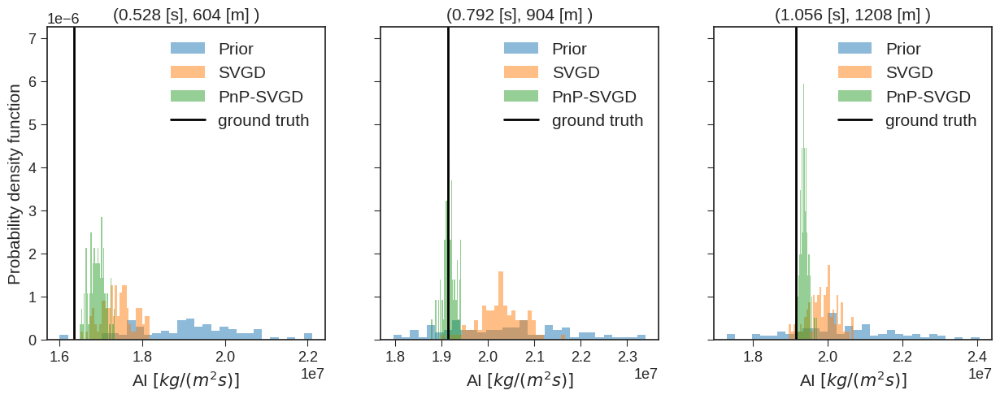

In [15]:
fig, axs = plt.subplots(1, 3, sharey=True, figsize=(15, 5))
num_bins = 30
axs[0].hist(torch.exp(X_init).reshape(num_particles, nt0, nx)[:, nt0//3, nx//3].detach().numpy(), 
            bins=num_bins, density=True, alpha=0.5, label='Prior')
axs[0].hist(torch.exp(Xsvgd).reshape(num_particles, nt0, nx)[:, nt0//3, nx//3].detach().numpy(), 
            bins=num_bins, density=True, alpha=0.5, label='SVGD')
axs[0].hist(torch.exp(X).reshape(num_particles, nt0, nx)[:, nt0//3, nx//3].detach().numpy(), 
            bins=num_bins, density=True, alpha=0.5, label='PnP-SVGD')
axs[0].axvline(np.exp(m[nt0//3, nx//3]), c='k', lw=2, label='ground truth')
axs[0].set_xlabel(r'AI $[kg/(m^2s)]$')
axs[0].set_ylabel('Probability density function')
axs[0].set_title(f'({t0[nt0//3]} [s], {x[nx//3]} [m] )')
axs[0].set_aspect('auto', 'datalim')
axs[0].legend(loc='upper right')


axs[1].hist(torch.exp(X_init).reshape(num_particles, nt0, nx)[:, nt0//2, nx//2].detach().numpy(), 
            bins=num_bins, density=True, alpha=0.5, label='Prior')
axs[1].hist(torch.exp(Xsvgd).reshape(num_particles, nt0, nx)[:, nt0//2, nx//2].detach().numpy(), 
            bins=num_bins, density=True, alpha=0.5, label='SVGD')
axs[1].hist(torch.exp(X).reshape(num_particles, nt0, nx)[:, nt0//2, nx//2].detach().numpy(), 
            bins=num_bins, density=True, alpha=0.5, label='PnP-SVGD')
axs[1].axvline(np.exp(m[nt0//2, nx//2]), c='k', lw=2, label='ground truth')
axs[1].set_xlabel(r'AI $[kg/(m^2s)]$')
# axs[1].set_ylabel('Probability density function')
axs[1].set_title(f'({t0[nt0//2]} [s], {x[nx//2]} [m] )')
axs[1].set_aspect('auto', 'datalim')
axs[1].legend(loc='upper right')

axs[2].hist(torch.exp(X_init).reshape(num_particles, nt0, nx)[:, 2*nt0//3, 2*nx//3].detach().numpy(), 
            bins=num_bins, density=True, alpha=0.5, label='Prior')
axs[2].hist(torch.exp(Xsvgd).reshape(num_particles, nt0, nx)[:, 2*nt0//3, 2*nx//3].detach().numpy(), 
            bins=num_bins, density=True, alpha=0.5, label='SVGD')
axs[2].hist(torch.exp(X).reshape(num_particles, nt0, nx)[:, 2*nt0//3, 2*nx//3].detach().numpy(), 
            bins=num_bins, density=True, alpha=0.5, label='PnP-SVGD')
axs[2].axvline(np.exp(m[2*nt0//3, 2*nx//3]), c='k', lw=2, label='ground truth')
axs[2].set_xlabel(r'AI $[kg/(m^2s)]$')
# axs[2].set_ylabel('Probability density function')
axs[2].set_title(f'({t0[2*nt0//3]} [s], {x[2*nx//3]} [m] )')
axs[2].set_aspect('auto', 'datalim')
axs[2].legend(loc='upper right')

# plt.savefig('../figures/hess/3-1-hess-hist.eps', dpi=300, bbox_inches="tight")
# plt.savefig('../figures/hess/3-1-hess-hist.png', dpi=300, bbox_inches="tight")

Text(0, 0.5, '$t [s]$')

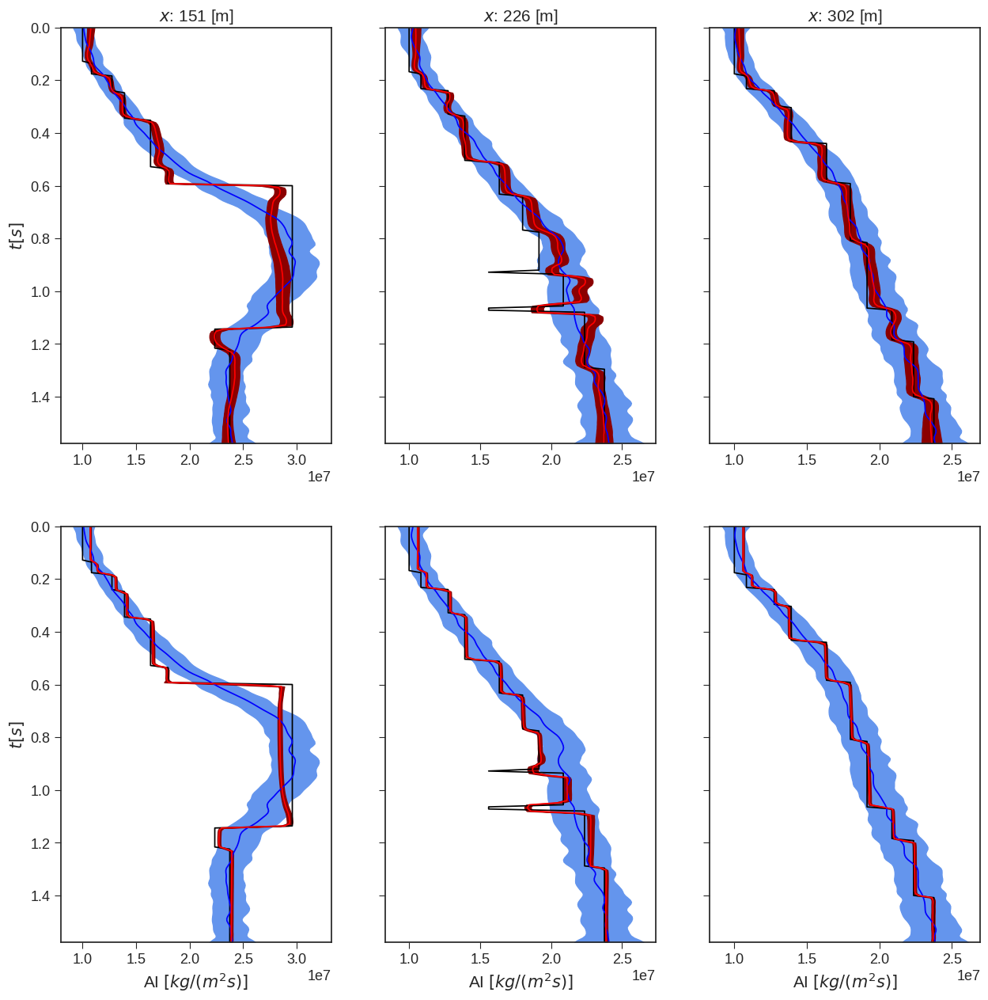

In [16]:
X_initmean, X_initstd = torch.exp(X_init).mean(0), torch.exp(X_init).std(0)
Xmean, Xstd = torch.exp(X).mean(0), torch.exp(X).std(0)
Xsvgdmean, Xsvgdstd = torch.exp(Xsvgd).mean(0), torch.exp(Xsvgd).std(0)

fig, axs = plt.subplots(2, 3, sharey=True, figsize=(15, 15))

for i, ix in enumerate([nx//3, nx//2, 2*nx//3]):
    #svgd
    axs[0, i].plot(np.exp(m[:, ix]), t0, 'k', linewidth=1.25)
#     axs[i].plot(np.exp(mdrunet[:, ix]), t0, 'limegreen', linewidth=1.25)
    axs[0, i].plot(X_initmean.reshape(nt0, nx)[:, ix].detach().numpy(), t0, 'b', linewidth=1.25)
    axs[0, i].fill_betweenx(t0, 
                        X_initmean.reshape(nt0, nx)[:, ix].detach().numpy() - 
                        X_initstd.reshape(nt0, nx)[:, ix].detach().numpy(), 
                        X_initmean.reshape(nt0, nx)[:, ix].detach().numpy() + 
                        X_initstd.reshape(nt0, nx)[:, ix].detach().numpy(),
                        color='cornflowerblue')
    axs[0, i].plot(Xsvgdmean.reshape(nt0, nx)[:, ix].detach().numpy(), t0, 'r', linewidth=1.25)
    axs[0, i].fill_betweenx(t0, 
                        Xsvgdmean.reshape(nt0, nx)[:, ix].detach().numpy() - 
                        Xsvgdstd.reshape(nt0, nx)[:, ix].detach().numpy(), 
                        Xsvgdmean.reshape(nt0, nx)[:, ix].detach().numpy() + 
                        Xsvgdstd.reshape(nt0, nx)[:, ix].detach().numpy(),
                        color='darkred')
#     axs[0, i].set_xlabel(r'AI $[kg/(m^2s)]$')
#     axs[0, i].set_xticklabels([])
    axs[0, i].set_title(f'$x$: {ix} [m]')
    axs[0, i].set_aspect('auto', 'datalim')
    
    #pnp-svgd
    axs[1, i].plot(np.exp(m[:, ix]), t0, 'k', linewidth=1.25)
#     axs[i].plot(np.exp(mdrunet[:, ix]), t0, 'limegreen', linewidth=1.25)
    axs[1, i].plot(X_initmean.reshape(nt0, nx)[:, ix].detach().numpy(), t0, 'b', linewidth=1.25)
    axs[1, i].fill_betweenx(t0, 
                        X_initmean.reshape(nt0, nx)[:, ix].detach().numpy() - 
                        X_initstd.reshape(nt0, nx)[:, ix].detach().numpy(), 
                        X_initmean.reshape(nt0, nx)[:, ix].detach().numpy() + 
                        X_initstd.reshape(nt0, nx)[:, ix].detach().numpy(),
                        color='cornflowerblue')
    axs[1, i].plot(Xmean.reshape(nt0, nx)[:, ix].detach().numpy(), t0, 'r', linewidth=1.25)
    axs[1, i].fill_betweenx(t0, 
                        Xmean.reshape(nt0, nx)[:, ix].detach().numpy() - 
                        Xstd.reshape(nt0, nx)[:, ix].detach().numpy(), 
                        Xmean.reshape(nt0, nx)[:, ix].detach().numpy() + 
                        Xstd.reshape(nt0, nx)[:, ix].detach().numpy(),
                        color='darkred')
    axs[1, i].set_xlabel(r'AI $[kg/(m^2s)]$')
    axs[1, i].set_aspect('auto', 'datalim')
#     axs[0, i].set_title(f'$x$: {ix} [m]')
    
axs[0, 0].set_ylim(t0[0], t0[-1])
axs[0, 0].set_ylabel(r'$t [s]$')

axs[1, 0].invert_yaxis()
axs[1, 0].set_ylabel(r'$t [s]$')
# plt.savefig('../figures/hess/3-1-hess-traces.eps', dpi=300, bbox_inches="tight")
# plt.savefig('../figures/hess/3-1-hess-traces.png', dpi=300, bbox_inches="tight")

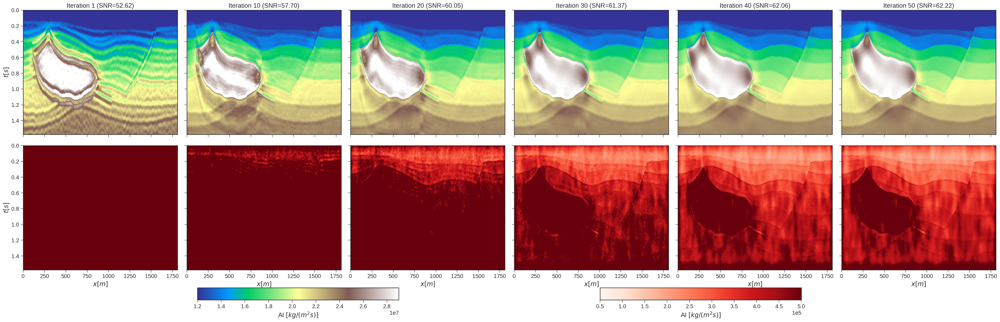

In [17]:
# svgd
plt.rcParams['font.size'] = '15'

iiter = np.array([1, 10, 20, 30, 40, 50])
fig, axs = plt.subplots(2, 6, sharex=True, sharey=True, figsize=(33,10), dpi=150)
vmin, vmax = 1.2e7, 2.9e7
for i, k in enumerate(iiter):
    axi=axs[0, i].imshow(Xsvgdmeancol[i].reshape(nt0, nx), vmin=vmin, vmax=vmax, cmap="terrain",
                     interpolation='sinc', extent=(x[0], x[-1], t0[-1], t0[0]))
    axs[0, i].set_title(f'Iteration {k} (SNR={snr(np.exp(m).ravel(), Xsvgdmeancol[i]):.2f})')
    axs[0, i].axis('tight')
    axs[0, i].set_aspect('auto', 'datalim')
#     axs[0, i].set_xlabel(r'$x [m]$')
    if i == 0: axs[0, 0].set_ylabel(r'$t [s]$')

vmin, vmax = 5e4, 5e5
for i, k in enumerate(iiter):
    axi2=axs[1, i].imshow(Xsvgdstdcol[i].reshape(nt0, nx), vmin=vmin, vmax=vmax, cmap='Reds',
                     interpolation='sinc', extent=(x[0], x[-1], t0[-1], t0[0]))
#     axs[1, i].set_title('Iteration %d' % k)
    axs[1, i].axis('tight')
    axs[1, i].set_xlabel(r'$x [m]$')
    axs[1, i].set_aspect('auto', 'datalim')
    if i == 0: axs[1, 0].set_ylabel(r'$t [s]$')
fig.tight_layout()
fig.subplots_adjust(bottom=0.1)

cbar_ax1 = fig.add_axes([0.2, 0.001, 0.2, 0.04])
cbar1 = fig.colorbar(axi, cax=cbar_ax1, orientation='horizontal')
cbar1.set_label(r'AI $[kg/(m^2s)]$')

cbar_ax2 = fig.add_axes([0.6, 0.001, 0.2, 0.04])
cbar2 = fig.colorbar(axi2, cax=cbar_ax2, orientation='horizontal')
cbar2.formatter.set_scientific(True)
cbar2.formatter.set_powerlimits((0,0))
cbar2.update_ticks()
cbar2.set_label(r'AI $[kg/(m^2s)]$')

# plt.savefig('../figures/hess/3-1-hess-svgd-evo.eps', dpi=300, bbox_inches="tight")
# plt.savefig('../figures/hess/3-1-hess-svgd-evo.png', dpi=300, bbox_inches="tight")

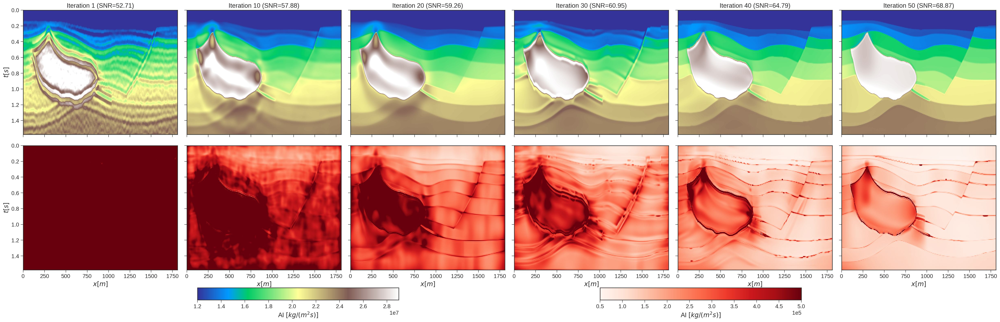

In [18]:
plt.rcParams['font.size'] = '15'

iiter = np.array([1, 10, 20, 30, 40, 50])
fig, axs = plt.subplots(2, 6, sharex=True, sharey=True, figsize=(33,10), dpi=150)
vmin, vmax = 1.2e7, 2.9e7
for i, k in enumerate(iiter):
    axi=axs[0, i].imshow(Xmeancol[i].reshape(nt0, nx), vmin=vmin, vmax=vmax, cmap="terrain",
                     interpolation='sinc', extent=(x[0], x[-1], t0[-1], t0[0]))
    axs[0, i].set_title(f'Iteration {k} (SNR={snr(np.exp(m).ravel(), Xmeancol[i]):.2f})')
    axs[0, i].axis('tight')
    axs[0, i].set_aspect('auto', 'datalim')
#     axs[0, i].set_xlabel(r'$x [m]$')
    if i == 0: axs[0, 0].set_ylabel(r'$t [s]$')

vmin, vmax = 5e4, 5e5
for i, k in enumerate(iiter):
    axi2=axs[1, i].imshow(Xstdcol[i].reshape(nt0, nx), vmin=vmin, vmax=vmax, cmap='Reds',
                     interpolation='sinc', extent=(x[0], x[-1], t0[-1], t0[0]))
#     axs[1, i].set_title('Iteration %d' % k)
    axs[1, i].axis('tight')
    axs[1, i].set_xlabel(r'$x [m]$')
    axs[1, i].set_aspect('auto', 'datalim')
    if i == 0: axs[1, 0].set_ylabel(r'$t [s]$')
fig.tight_layout()
fig.subplots_adjust(bottom=0.1)

cbar_ax1 = fig.add_axes([0.2, 0.001, 0.2, 0.04])
cbar1 = fig.colorbar(axi, cax=cbar_ax1, orientation='horizontal')
cbar1.set_label(r'AI $[kg/(m^2s)]$')

cbar_ax2 = fig.add_axes([0.6, 0.001, 0.2, 0.04])
cbar2 = fig.colorbar(axi2, cax=cbar_ax2, orientation='horizontal')
cbar2.formatter.set_scientific(True)
cbar2.formatter.set_powerlimits((0,0))
cbar2.update_ticks()
cbar2.set_label(r'AI $[kg/(m^2s)]$')

# plt.savefig('../figures/hess/3-1-hess-evo.eps', dpi=300, bbox_inches="tight")
# plt.savefig('../figures/hess/3-1-hess-evo.png', dpi=300, bbox_inches="tight")

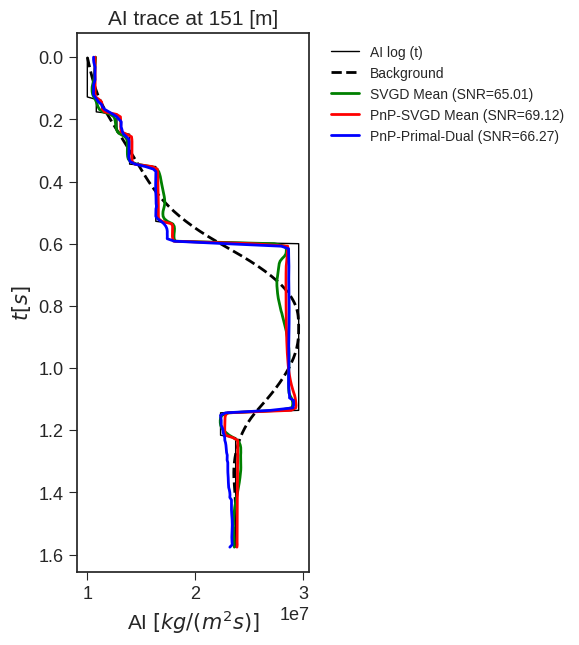

In [19]:
# Interpolate well log at resolution of estimated AI and compare with estimates

fig, ax = plt.subplots(1, 1, figsize=(3, 7))
ax.plot(np.exp(m[:, nx//3]), t0, 'k', lw=1, label='AI log (t)')
ax.plot(np.exp(mback[:, nx//3]), t0, '--k', lw=2, label='Background')
ax.plot(Xsvgdmean.numpy().reshape(nt0, nx)[:, nx//3], t0, 'g', lw=2, 
        label='SVGD Mean (SNR=%.2f)' % snr(np.exp(m[:, nx//3]), Xsvgdmean.numpy().reshape(nt0, nx)[:, nx//3]))
ax.plot(Xmean.numpy().reshape(nt0, nx)[:, nx//3], t0, 'r', lw=2, 
        label='PnP-SVGD Mean (SNR=%.2f)' % snr(np.exp(m[:, nx//3]), Xmean.numpy().reshape(nt0, nx)[:, nx//3]))
ax.plot(np.exp(mdrunet.reshape(nt0, nx))[:, nx//3], t0, 'b', lw=2, 
        label='PnP-Primal-Dual (SNR=%.2f)' % snr(np.exp(m[:, nx//3]), np.exp(mdrunet.reshape(nt0, nx))[:, nx//3]))
ax.invert_yaxis()
ax.set_title(f'AI trace at {nx//3} [m]')
ax.set_ylabel(r'$t [s]$')
ax.set_xlabel(r'AI $[kg/(m^2s)]$')
ax.set_aspect('auto', 'datalim')
# ax.set_ylim(2800, 2100)
leg = ax.legend(loc=1, prop={'size': 10}, bbox_to_anchor=(2.15, 1 ))
# plt.savefig('../figures/hess/3-1-hess-well-log.eps', dpi=300, bbox_inches="tight")
# plt.savefig('../figures/hess/3-1-hess-well-log.png', dpi=300, bbox_inches="tight")

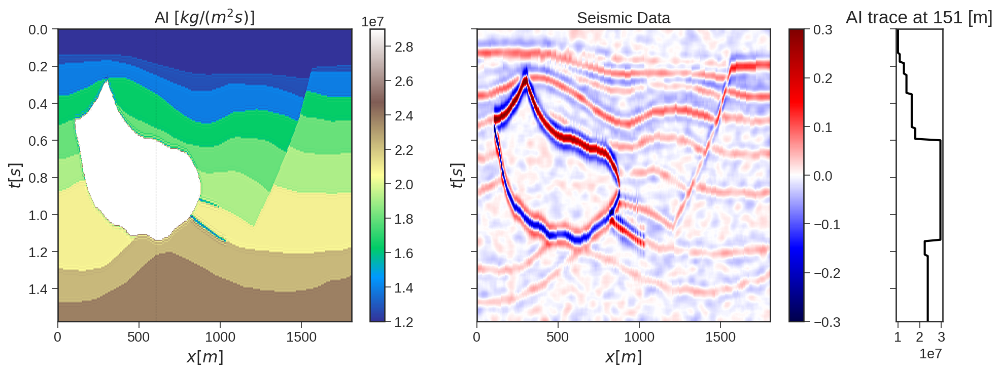

In [20]:
fig, axs = plt.subplots(1, 3, sharey=True, figsize=(15, 5), dpi=150,
                       gridspec_kw={'width_ratios': [5.5, 5.5, 0.7]})
im1 = axs[0].imshow(np.exp(m), vmin=1.2e7, vmax=2.9e7, cmap='terrain', 
                    extent=(x[0], x[-1], t0[-1], t0[0]), interpolation='sinc')
axs[0].axvline(x[nx//3], c='k', ls='--', lw=0.5)
axs[0].set_title(r'AI $[kg/(m^2s)]$')
axs[0].set_ylabel(r'$t [s]$')
axs[0].set_xlabel(r'$x [m]$')
axs[0].axis('tight')
axs[0].set_aspect('auto', 'datalim')
plt.colorbar(im1, ax=axs[0])

im2 = axs[1].imshow(dn, cmap='seismic', vmin=-0.3, vmax=0.3, 
                    extent=(x[0], x[-1], t0[-1], t0[0]), interpolation='sinc')
axs[1].set_title(r'Seismic Data')
axs[1].set_ylabel(r'$t [s]$')
axs[1].set_xlabel(r'$x [m]$')
axs[1].axis('tight')
axs[1].set_aspect('auto', 'datalim')
plt.colorbar(im2, ax=axs[1])

axs[2].plot(np.exp(m[:, nx//3]), t0, 'k', lw=2)
axs[2].axis('tight')
axs[2].set_title(f'AI trace at {nx//3} [m]', fontsize=17)
axs[2].set_aspect('auto', 'datalim')
# plt.savefig('../figures/hess/3-1-hess-data.eps', dpi=300, bbox_inches="tight")
# plt.savefig('../figures/hess/3-1-hess-data.png', dpi=300, bbox_inches="tight")